In [1]:
import numpy as np
import ot_utils
import comparison_utils
from tqdm import tqdm
import math
import matplotlib.pyplot as plt
from sklearn.metrics import pairwise_distances

local_project_path = ''

# please create a local_dataset_path.txt file that contains the path to the folder that contains the JetClass Dataset
with open('project_path.txt') as f:
    local_project_path = f.read()

num_jets_per_class = 4000
HToBB_matrix = np.load(local_project_path + "medium_ps/ps_block_1_1.npy")
labels = np.zeros(num_jets_per_class)

In [5]:
import utils.comparison_utils

ModuleNotFoundError: No module named 'utils.comparison_utils'

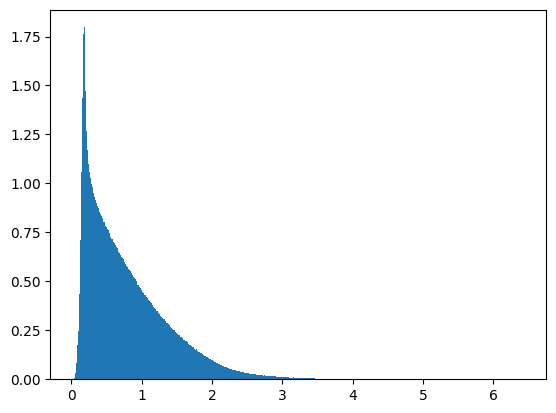

In [2]:
i_ut, j_ut = np.triu_indices(4000, k=1)

unique_distances = HToBB_matrix[i_ut, j_ut]

plt.hist(unique_distances, bins='fd', density=True)
plt.show()

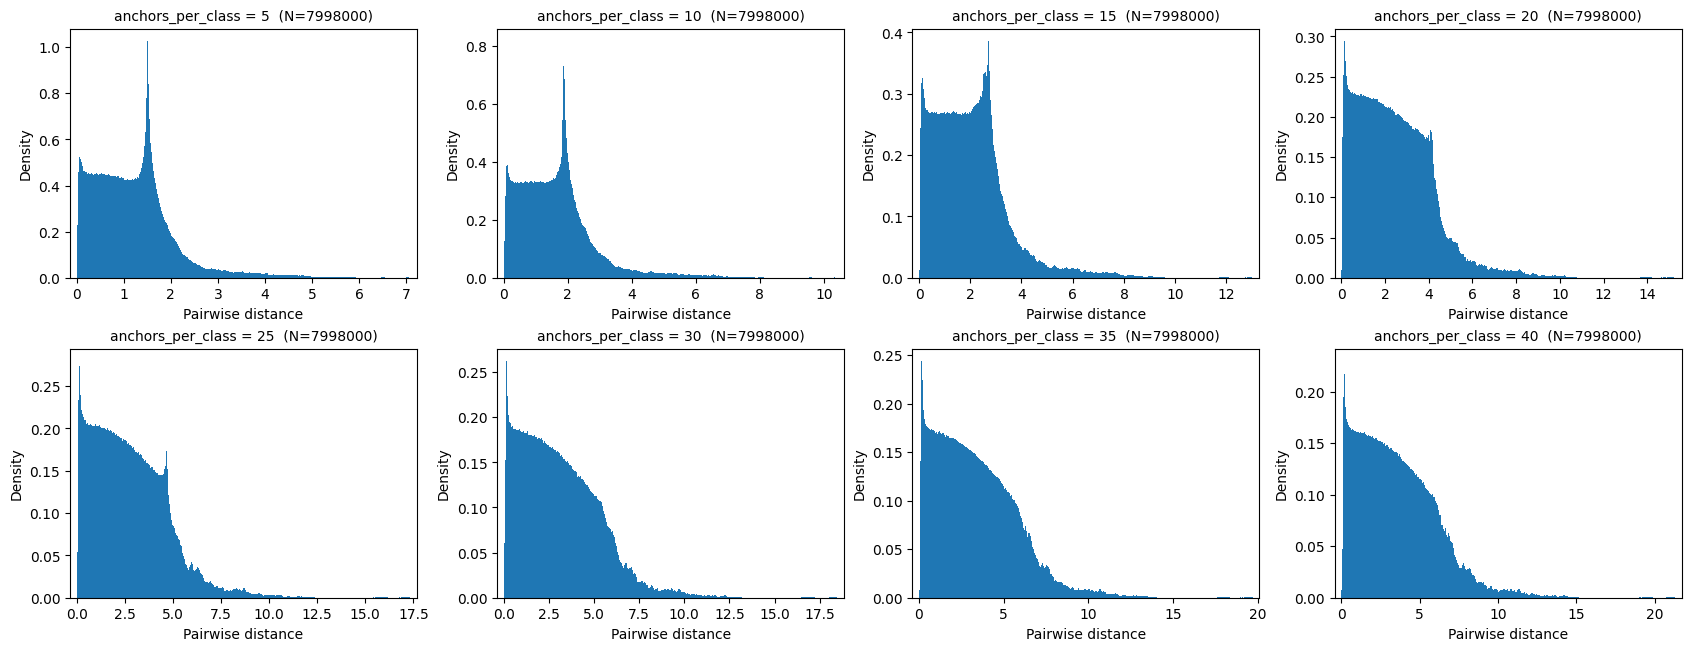

In [3]:
def _uniq_pairwise_dist(rel_rep, i_ut=None, j_ut=None):
    n = rel_rep.shape[0]
    if i_ut is None or j_ut is None:
        i_ut, j_ut = np.triu_indices(n, k=1)

    dmat = np.zeros((n, n), dtype=float)
    for i, j in zip(i_ut, j_ut):
        d = comparison_utils.eud_dist(rel_rep[i], rel_rep[j])
        dmat[i, j] = d
        dmat[j, i] = d
    return dmat[i_ut, j_ut]

def pairwise_distance_matrix(rel_rep, i_ut=None, j_ut=None):
    n = rel_rep.shape[0]
    if i_ut is None or j_ut is None:
        i_ut, j_ut = np.triu_indices(n, k=1)

    dmat = np.zeros((n, n), dtype=float)
    for i, j in zip(i_ut, j_ut):
        d = comparison_utils.eud_dist(rel_rep[i], rel_rep[j])
        dmat[i, j] = d
        dmat[j, i] = d
        
    return dmat

def pairwise_hist_for_anchors(
    anchor_values,
    HToBB_matrix,
    labels,
    num_classes=1,
    num_jets_per_class=None,
    i_ut=None,
    j_ut=None,
    seed=42,
    bins="fd",        # <-- per-panel binning (use "fd", "auto", or an int)
    density=False,    # True = shape-only comparison
    ncols=4,          # 4 per row
):
    if (i_ut is None) or (j_ut is None):
        n = num_jets_per_class if num_jets_per_class is not None else len(labels)
        i_ut, j_ut = np.triu_indices(n, k=1)

    results = []
    distance_matrices = []
    for a in anchor_values:
        rel_rep = comparison_utils.relative_rep(
            HToBB_matrix,
            labels=labels,
            num_classes=num_classes,
            anchors_per_class=a,
            seed=seed
        )
        uniq_d = _uniq_pairwise_dist(rel_rep, i_ut=i_ut, j_ut=j_ut)
        distance_matrix = pairwise_distance_matrix(rel_rep, i_ut=i_ut, j_ut=j_ut)
        results.append((a, uniq_d))
        distance_matrices.append(distance_matrix)


    nrows = math.ceil(len(results) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(ncols * 4.2, nrows * 3.2),
        constrained_layout=True
    )
    axes = np.ravel(axes)

    for ax, (a, uniq_d) in zip(axes, results):
        # Each panel computes its own bins and x-scale
        ax.hist(uniq_d, bins=bins, density=density)
        ax.set_title(f"anchors_per_class = {a}  (N={uniq_d.size})", fontsize=10)
        ax.set_xlabel("Pairwise distance")
        ax.set_ylabel("Density" if density else "Count")
        # Make x-limits snug to the data (with a tiny pad)
        lo, hi = np.min(uniq_d), np.max(uniq_d)
        if hi > lo:
            pad = 0.02 * (hi - lo)
            ax.set_xlim(lo - pad, hi + pad)

    for ax in axes[len(results):]:
        ax.axis("off")

    plt.show()
    return results, distance_matrices, fig

anchor_values = list(range(5, 41, 5))
results, distance_matrices, fig = pairwise_hist_for_anchors(
    anchor_values,
    HToBB_matrix,
    labels,
    num_classes=1,
    i_ut=i_ut, j_ut=j_ut,     # reuse your existing pairs if you have them
    seed=42,
    bins="fd",                # per-panel bins; change to an int (e.g., 100) if you want fixed count per panel
    density=True,
    ncols=4
)

In [4]:
# HToBB_rel_rep = comparison_utils.relative_rep(
#     HToBB_matrix, labels=labels, num_classes=1, anchors_per_class=10, seed=42
# )

# HToBB_ps_pairwise_euc = np.zeros((num_jets_per_class, num_jets_per_class))

# for i, j in tqdm(zip(i_ut, j_ut), total=len(i_ut)):
#     HToBB_ps_pairwise_euc[i, j] = comparison_utils.eud_dist(
#         HToBB_rel_rep[i], HToBB_rel_rep[j]
#     )
#     HToBB_ps_pairwise_euc[j, i] = HToBB_ps_pairwise_euc[i, j]
    
# uniq_rel_rep_dist = HToBB_ps_pairwise_euc[i_ut, j_ut]

# plt.hist(uniq_rel_rep_dist, bins=100)
# plt.show()

100%|██████████| 100/100 [03:06<00:00,  1.86s/it]


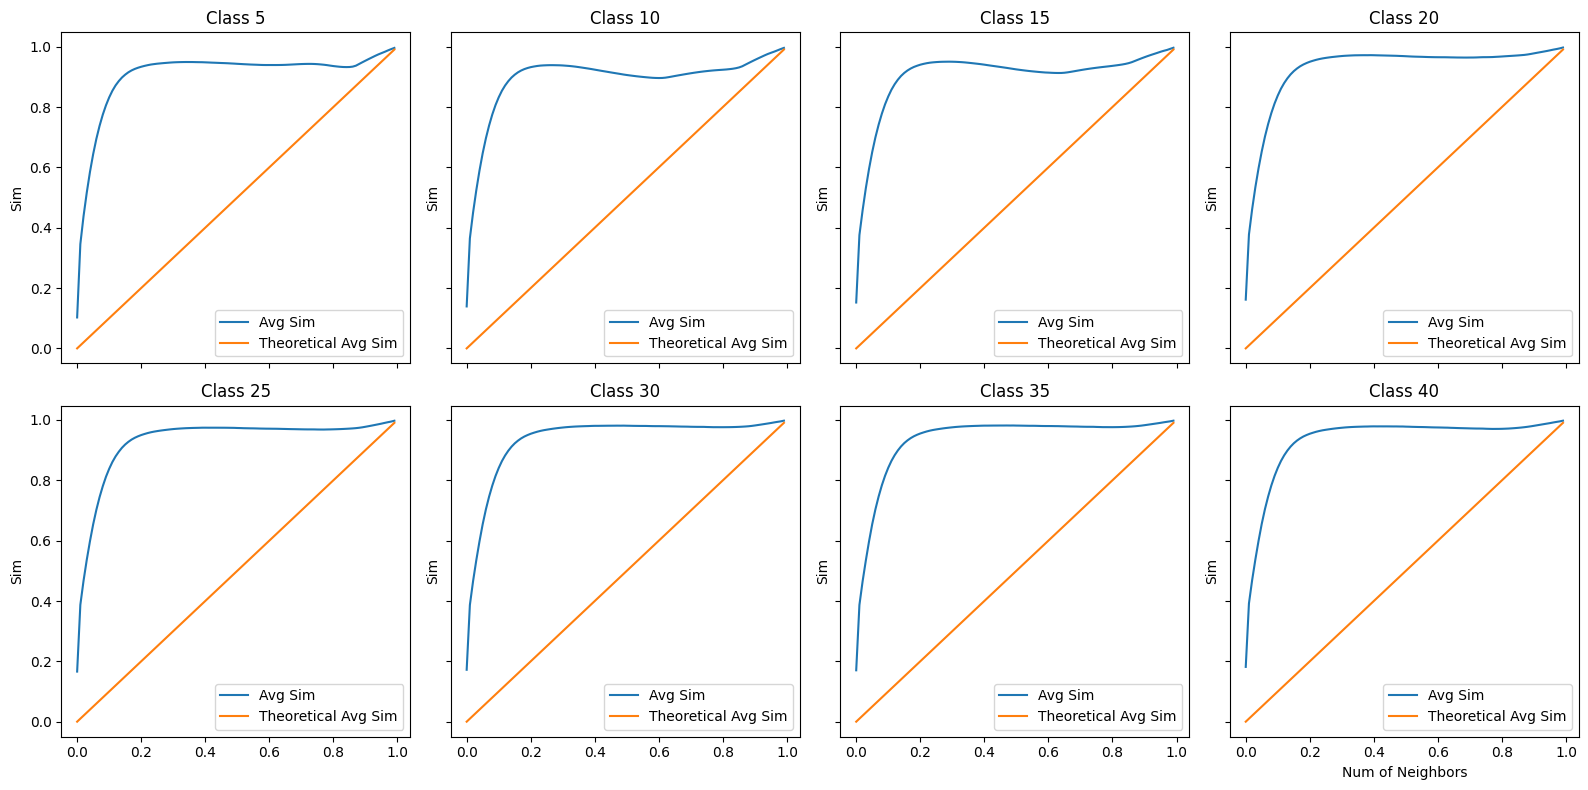

In [5]:
neighbors_list = np.arange(1, 3999, 40)

theoretical_avg_sim = neighbors_list / (4000 - 1)

n_plots = len(anchor_values)
ncols = 4
nrows = int(np.ceil(n_plots / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows), sharex=True, sharey=True)
axes = axes.flatten()

avg_strict_jaccard_sims = np.zeros((n_plots, len(neighbors_list)))

neighbor_percentage = neighbors_list / 4000

i = 0
for ax, anchor_value in zip(axes, anchor_values):
    for j, n_neighbors in tqdm(enumerate(neighbors_list), total = len(neighbors_list)):
        avg_strict_jaccard_sims[i][j] = comparison_utils.average_strict_jaccard(HToBB_matrix, distance_matrices[i], n_neighbors=n_neighbors)
        
    ax.plot(neighbor_percentage, avg_strict_jaccard_sims[i], label='Avg Sim')
    ax.plot(neighbor_percentage, theoretical_avg_sim, label='Theoretical Avg Sim')
    ax.set_title(f'Class {anchor_value}')
    ax.set_ylabel('Sim')
    ax.legend()
    i = i+1

# common X-axis label on bottom
axes[-1].set_xlabel('Num of Neighbors')


plt.tight_layout()
plt.show()

In [6]:
print(np.mean(avg_strict_jaccard_sims,axis=1))

[0.9030024  0.88838984 0.89966502 0.92442346 0.92676506 0.93219451
 0.93269555 0.930323  ]


In [7]:
from scipy.integrate import simpson

aucs_scipy = np.zeros(len(anchor_values))
for i in range(len(anchor_values)):
    aucs_scipy[i] = simpson(y=avg_strict_jaccard_sims[i], x=neighbor_percentage)
    
print(np.round(aucs_scipy, 3))

aucs_numpy = np.zeros(len(anchor_values))
for i in range(len(anchor_values)):
    aucs_numpy[i] = np.trapz(y=avg_strict_jaccard_sims[i], x=neighbor_percentage)
print(np.round(aucs_numpy, 3))

[0.898 0.883 0.894 0.919 0.921 0.927 0.927 0.925]
[0.898 0.883 0.894 0.919 0.921 0.926 0.927 0.924]
